# Pretrained encoders for whole-slide classification

Compare **original UNI (histopathology)**, **DINO ViT-S/16 (ImageNet self-supervision)** and **ResNet-50 (ImageNet supervision)** on the same ten TCGA-LUAD/LUSC slides. Every eligible tissue patch in each declared coordinate export contributes to its slide bag.

The encoders remain frozen. An attention pool and diagnosis classifier learn from the **six training slides**, with two validation and two held-out slides. UNI with a trained classifier is a frozen-encoder transfer model, **not zero-shot diagnosis classification**. For encoder updates and random initialization, see the separate [brief training notebook](representation_learning_demo.ipynb).

This is a small teaching comparison, not a model ranking or a generalization/clinical benchmark. More patches do not create more independent patients.

**Saved execution:** Saved outputs compare DINO and ResNet-50; UNI remains configured but has not completed this comparison.


## 1. Local inputs, weights and execution budget

Use the locked environment and a fresh kernel. The existing input-preparation helper verifies the local TCGA assets and coordinate exports. All three encoders use the same 256-pixel tissue tiles at the recorded target 0.5 µm/pixel, explicitly resized to 224 pixels and ImageNet-normalized. This shared transform deliberately uses the entire square tile instead of each model's default center-crop recipe.

UNI is loaded through **TIMM's Hugging Face loader**, with a pinned revision and checksum. Sign in locally using `.venv/bin/hf auth login` after provider approval; never place a token in a notebook. Weights must be prepared before this run. The encoder cache uses `data/models/huggingface/hub` without changing the standard authentication location.

The current exports contain **48,621 eligible patches**. First extraction is substantial; completed caches are reused, matching partial caches can resume, and each slide has an explicit time bound. Memory is bounded by extraction batches; training uses complete bags of frozen embeddings. The default is Apple GPU when available, otherwise CPU; select explicitly if needed.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import hashlib
import json
import os
import sys
import subprocess
import time
import uuid

for variable in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[variable] = '1'
os.environ['HF_HUB_DISABLE_TELEMETRY'] = '1'

PROJECT = None  # Optional: Path(...) to this checkout.
if PROJECT is None:
    PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file() and (p / 'src/runners/train.py').is_file()), None)
    if PROJECT is None:
        raise FileNotFoundError('Open from this project or set PROJECT explicitly.')
PROJECT = Path(PROJECT).expanduser().resolve(strict=True)
sys.path.insert(0, str(PROJECT))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

CLASS_NAMES = ['LUAD', 'LUSC']
SEED = 42
TARGET_MPP = 0.5
ROSTER = PROJECT / 'manifests/tcga_demo.csv'
PREPROCESSING_RUN = PROJECT / 'outputs/tcga-mpp05'
subprocess.run([sys.executable, str(PROJECT / 'scripts/prepare_demo_inputs.py'),
                '--demo', 'wsi-classification', '--prepare-coordinates',
                '--preprocessing-run', str(PREPROCESSING_RUN)], check=True, cwd=PROJECT)
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
OUT = PROJECT / 'outputs/wsi_classification_demo' / run_id
OUT.mkdir(parents=True, exist_ok=False)
started = time.monotonic()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

import torch
from omegaconf import OmegaConf
from src.data.coordinates import complete_coordinate_manifest
from src.training.wsi_comparison import run_comparison
torch.set_num_threads(2)
DEVICE = 'mps' if torch.backends.mps.is_available() else 'cpu'
CACHE = PROJECT / 'outputs/wsi_features_v1'
settings = OmegaConf.to_container(OmegaConf.load(PROJECT / 'configs/wsi_comparison.yaml'), resolve=True)
print('Device:', DEVICE)
print('Kernel:', sys.executable)
print('Outputs:', OUT)


Matplotlib is building the font cache; this may take a moment.


{
  "demo": "wsi-classification",
  "project": "/Users/irina/Projects/digital-pathology-demo",
  "commands_run": [],
  "missing": [],
  "tcga": {
    "slides": 10,
    "bytes": 2983934214,
    "integrity_check": "GDC size and MD5",
    "missing_before": []
  },
  "models": {
    "dino": {
      "integrity_check": "pinned size and SHA-256",
      "missing_before": []
    }
  },
  "preprocessing": {
    "path": "/Users/irina/Projects/digital-pathology-demo/outputs/tcga-mpp05",
    "slides": 10,
    "mask_method": "clam_saturation",
    "integrity_check": "manifest identity, input sizes and HDF5 shape/calibration; downstream loader validates coordinates"
  },
  "status": "ready"
}


Device: mps
Kernel: /Users/irina/Projects/digital-pathology-demo/.venv/bin/python
Outputs: /Users/irina/Projects/digital-pathology-demo/outputs/learning_recipes_validation_20261103/classification-publish-validation/runs/20261103T212408Z_cbe103f2


## 2. Assign patients to splits before reading patches

Each local slide has a declared participant and LUAD/LUSC project label. This demo requires five distinct participants per class and one slide per participant. Within each class, a seeded permutation assigns three participants to training, one to validation and one to test: **6 / 2 / 2 patients**, with both labels represented in each split.

The preparation script verifies each WSI against the provider size and MD5 checksum before this step. The notebook then checks metadata and coordinate identity and records coordinate hashes. Later size/mtime checks detect source changes during the run; they do not replace the initial full-file check.


In [2]:
with ROSTER.open(newline='') as stream:
    roster = list(csv.DictReader(stream))
preprocessing_manifest_path = PREPROCESSING_RUN / 'manifest.json'
preprocessing = json.loads(preprocessing_manifest_path.read_text())
assert preprocessing['status'] == 'complete'
assert len(roster) == len(preprocessing['slides']) == 10
slides = {Path(slide['input']).stem: slide for slide in preprocessing['slides']}
assert len(slides) == 10 and len({row['case_submitter_id'] for row in roster}) == 10
assert len({row['case_id'] for row in roster}) == 10
assert all(row['case_submitter_id'].strip() and row['case_id'].strip() for row in roster)
rng = np.random.default_rng(SEED)
assignments = {}
for label in CLASS_NAMES:
    cohort = sorted((row for row in roster if row['label'] == label), key=lambda row: row['case_submitter_id'])
    assert len(cohort) == 5
    ordered = [cohort[i] for i in rng.permutation(len(cohort))]
    for row, split in zip(ordered, ['train', 'train', 'train', 'val', 'test'], strict=True):
        assignments[row['case_submitter_id']] = split
rows, source_state = [], {}
for row in sorted(roster, key=lambda row: (row['label'], row['case_submitter_id'])):
    slide = slides[row['file_id']]
    wsi = (PROJECT / row['path']).resolve(strict=True)
    assert wsi == (PROJECT / slide['input']).resolve(strict=True)
    assert slide['name'] == row['case_submitter_id'] and slide['case_id'] == row['case_id']
    assert slide['label'] == row['label']
    assert wsi.stat().st_size == int(row['file_size'])
    layouts = [item for item in slide['exports']['layouts']
               if item['patch_size'] == 256 and item.get('target_mpp') == TARGET_MPP]
    assert len(layouts) == 1
    layout = layouts[0]
    assert layout['exported_count'] == layout['eligible_count'] > 0
    coords_path = (PREPROCESSING_RUN / layout['coords']).resolve(strict=True)
    rows.append({'wsi_path': str(wsi), 'coords_path': str(coords_path),
        'split': assignments[row['case_submitter_id']], 'group_id': row['case_submitter_id'],
        'label': CLASS_NAMES.index(row['label']), 'bag_id': row['file_id'],
        'case_id': row['case_id'], 'source_md5': row['md5sum'], 'source_size_bytes': row['file_size']})
    source_state[row['file_id']] = {'path': str(wsi), 'size_bytes': wsi.stat().st_size,
        'mtime_ns': wsi.stat().st_mtime_ns, 'provider_md5_declared': row['md5sum'],
        'full_wsi_checksum_verified_this_run': True, 'coords_path': str(coords_path),
        'coords_sha256': sha256(coords_path)}
manifest = OUT / 'wsi_splits.csv'
with manifest.open('x', newline='') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
    writer.writeheader()
    writer.writerows(rows)
cohort_table = pd.DataFrame(rows)
assert cohort_table.groupby('group_id')['split'].nunique().max() == 1
assert cohort_table.groupby('bag_id')['split'].nunique().max() == 1
assert cohort_table['split'].value_counts().to_dict() == {'train': 6, 'val': 2, 'test': 2}
cohort_table['diagnosis'] = cohort_table['label'].map(dict(enumerate(CLASS_NAMES)))
display(cohort_table[['group_id', 'bag_id', 'diagnosis', 'split', 'source_size_bytes']])
display(pd.crosstab(cohort_table['split'], cohort_table['diagnosis']).reindex(['train', 'val', 'test']))
print('Preprocessing method:', preprocessing['mask_method'], 'schema:', preprocessing.get('schema_version'))
print('Every eligible coordinate in these exports will be used; no patch subsampling.')


,group_id,bag_id,diagnosis,split,source_size_bytes
0,TCGA-38-7271,481320d0-3239-4a35-9264-89ae40af4190,LUAD,test,250015391
1,TCGA-44-6775,f4bc3db8-eac1-4a1d-9049-dce8ced935a4,LUAD,val,398991369
2,TCGA-49-4507,afe0916c-b361-48f7-82dd-2fced9025e77,LUAD,train,648528537
3,TCGA-55-6972,20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b,LUAD,train,59772831
4,TCGA-75-5147,a9d2de24-b5a3-4b7b-961e-c3dcb47e1017,LUAD,train,131688074
5,TCGA-34-5232,4cae8c1a-195a-49d3-a88e-f863c6506ab2,LUSC,train,651794851
6,TCGA-43-7658,6016e929-ad86-4de4-a523-8ba4427d7f18,LUSC,train,134400649
7,TCGA-56-8083,1a872227-edc9-464c-8490-cb42d151c170,LUSC,val,57150809
8,TCGA-63-A5MG,c79b3182-2862-4af8-b0c9-f87fad9917c2,LUSC,train,250019834
9,TCGA-85-7698,5048c79f-ed1d-4534-8da2-1a4d207b2371,LUSC,test,401571869


diagnosis,LUAD,LUSC
split,,
train,3,3
val,1,1
test,1,1


Preprocessing method: clam_saturation schema: None
Every eligible coordinate in these exports will be used; no patch subsampling.


## 3. Audit complete patch coverage

Coordinates keep their original ordering and level-0 pixel frame. Each feature row is bound to one coordinate, the slide identity, calibration and verified encoder weights. L2 normalization acts independently on each embedding; no normalization is fitted on validation/test data. Patient split checks precede pixel reads.

In [3]:
items = complete_coordinate_manifest(manifest, PROJECT, class_names=CLASS_NAMES, target_mpp=TARGET_MPP)
coverage = pd.DataFrame([{'patient': i['row']['group_id'], 'split': i['row']['split'],
    'slide': i['row']['bag_id'], 'eligible_patches': i['eligible_patches']} for i in items])
assert len(items) == 10
coverage.to_csv(OUT / 'eligible_patch_coverage.csv', index=False)
display(coverage)
print('Patches per encoder:', int(coverage['eligible_patches'].sum()))
OmegaConf.save(OmegaConf.create(settings), OUT / 'comparison_config.yaml')

,patient,split,slide,eligible_patches
0,TCGA-38-7271,test,481320d0-3239-4a35-9264-89ae40af4190,5441
1,TCGA-44-6775,val,f4bc3db8-eac1-4a1d-9049-dce8ced935a4,6830
2,TCGA-49-4507,train,afe0916c-b361-48f7-82dd-2fced9025e77,11385
3,TCGA-55-6972,train,20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b,781
4,TCGA-75-5147,train,a9d2de24-b5a3-4b7b-961e-c3dcb47e1017,1684
5,TCGA-34-5232,train,4cae8c1a-195a-49d3-a88e-f863c6506ab2,10722
6,TCGA-43-7658,train,6016e929-ad86-4de4-a523-8ba4427d7f18,2129
7,TCGA-56-8083,val,1a872227-edc9-464c-8490-cb42d151c170,725
8,TCGA-63-A5MG,train,c79b3182-2862-4af8-b0c9-f87fad9917c2,3069
9,TCGA-85-7698,test,5048c79f-ed1d-4534-8da2-1a4d207b2371,5855


Patches per encoder: 48621


## 4. Extract once, train matched slide classifiers

Each model uses identical slides, coordinates, label order, seed, epoch budget and optimizer settings. The attention architecture is shared; parameter counts differ with encoder feature dimension and are reported. Every patch in a slide participates in each forward pass; no tissue patch receives an invented diagnosis label.

The notebook composes `experiment=mil_features` and calls the shared `src.runners.train.run` Lightning entrypoint. Training loss averages updates within each epoch; validation uses the end-of-epoch model. Checkpoint selection uses validation loss. The held-out pair is scored after selection. These two validation patients provide very unstable model selection; do not tune against held-out results.

In [4]:
comparison = run_comparison(items, PROJECT, OUT / 'comparison', CACHE, device=DEVICE, **settings)
assert comparison['status'] == 'complete' and comparison['same_bags_and_splits']
assert comparison['all_eligible_patches_per_model'] == int(coverage['eligible_patches'].sum())
assert all(r['optimizer_steps'] == 6 * settings['epochs'] for r in comparison['results'].values())
print('Completed models:', comparison['models'])

ENCODER dino


Seed set to 42


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..


... (18 outputs left out)

Restoring states from the checkpoint path at /Users/irina/Projects/digital-pathology-demo/outputs/learning_recipes_validation_20261103/classification-publish-validation/runs/20261103T212408Z_cbe103f2/comparison/resnet50/fit/checkpoints/epoch_019.ckpt


Loaded model weights from the checkpoint at /Users/irina/Projects/digital-pathology-demo/outputs/learning_recipes_validation_20261103/classification-publish-validation/runs/20261103T212408Z_cbe103f2/comparison/resnet50/fit/checkpoints/epoch_019.ckpt


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test/accuracy       │            1.0            │
│         test/loss         │    0.5749678611755371     │
└───────────────────────────┴───────────────────────────┘

Completed models: ['dino', 'resnet50']


## 5. Read actual learning curves and the small held-out comparison

Loss curves show optimization and possible overfitting, not guaranteed improvement. Accuracy on two held-out slides can only be 0, 0.5 or 1.0. Equal patch coverage controls one source of variation; pretraining data, architecture and feature dimensions still differ.

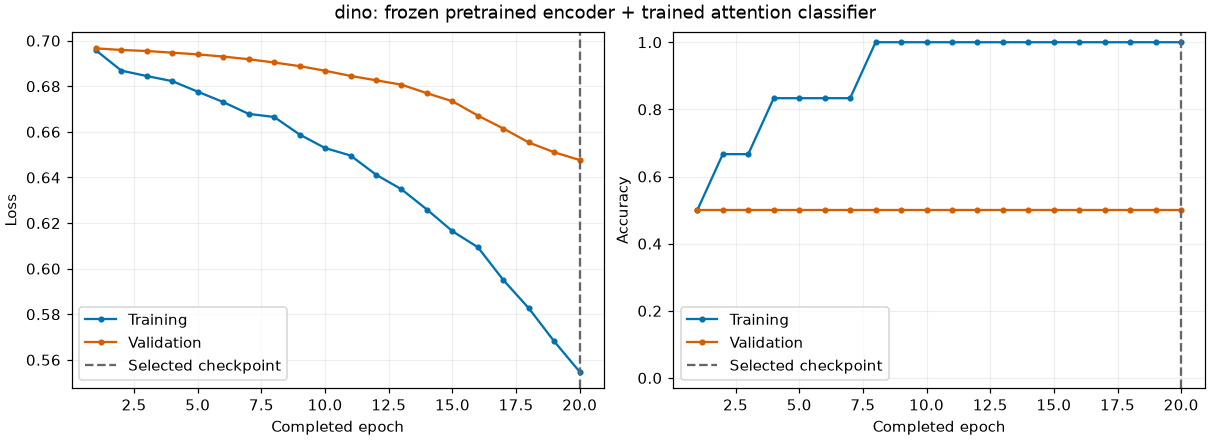

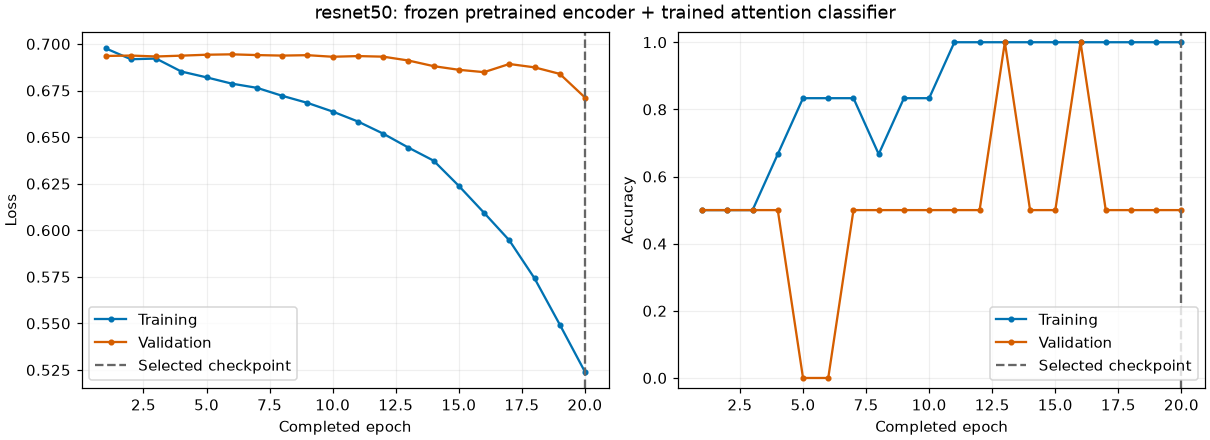

,encoder,selected_epoch,validation_loss,held_out_loss,held_out_accuracy,head_parameters,eligible_patches
0,dino,20,0.647647,0.577460,1.0,50179,48621
1,resnet50,20,0.671231,0.574968,1.0,266499,48621


,encoder,slide_id,patient_id,label,predicted_label,probabilities,patches
0,dino,481320d0-3239-4a35-9264-89ae40af4190,TCGA-38-7271,0,0,"[0.56827712059021, 0.43172287940979004]",5441
1,dino,5048c79f-ed1d-4534-8da2-1a4d207b2371,TCGA-85-7698,1,1,"[0.4455476403236389, 0.5544523596763611]",5855
2,resnet50,481320d0-3239-4a35-9264-89ae40af4190,TCGA-38-7271,0,0,"[0.625193178653717, 0.37480688095092773]",5441
3,resnet50,5048c79f-ed1d-4534-8da2-1a4d207b2371,TCGA-85-7698,1,1,"[0.4935051500797272, 0.5064948201179504]",5855


In [5]:
from IPython.display import Image as DisplayImage
summary = []
for name, result in comparison['results'].items():
    display(DisplayImage(filename=str(OUT / 'comparison' / name / 'learning_curve.png')))
    summary.append({'encoder': name, 'selected_epoch': result['selected_epoch'],
        'validation_loss': result['selected_val_loss'], 'held_out_loss': result['test_loss'],
        'held_out_accuracy': result['test_accuracy'], 'head_parameters': result['trainable_parameters'],
        'eligible_patches': sum(row['patches'] for row in result['inputs'])})
summary = pd.DataFrame(summary)
summary.to_csv(OUT / 'model_comparison.csv', index=False)
display(summary)
predictions = pd.DataFrame([{'encoder': name, **row} for name, r in comparison['results'].items()
                           for row in r['test_predictions']])
display(predictions)

## 6. Interpretation: where the model pools, and which pixels affect its score

**Whole-slide maps** show learned MIL pooling attention over every eligible patch. Colours are within-slide percentiles of attention; unscored regions remain uncovered. These are not calibrated tumour probabilities, cell annotations or transformer self-attention.

**Selected-patch saliency** differentiates the predicted slide-class logit through one patch while retaining all other patch embeddings. Highest-, median- and lowest-attention patches are selected deterministically. The gradient includes the effect on the attention pool. Each display is clipped at its own 99th percentile; raw maps are saved, so colours should not be compared quantitatively between panels.

Saliency is local sensitivity, not causal evidence or an annotation of disease. Both held-out slides are exported for every encoder; below, inspect the same selected slide across models.

dino 481320d0-3239-4a35-9264-89ae40af4190


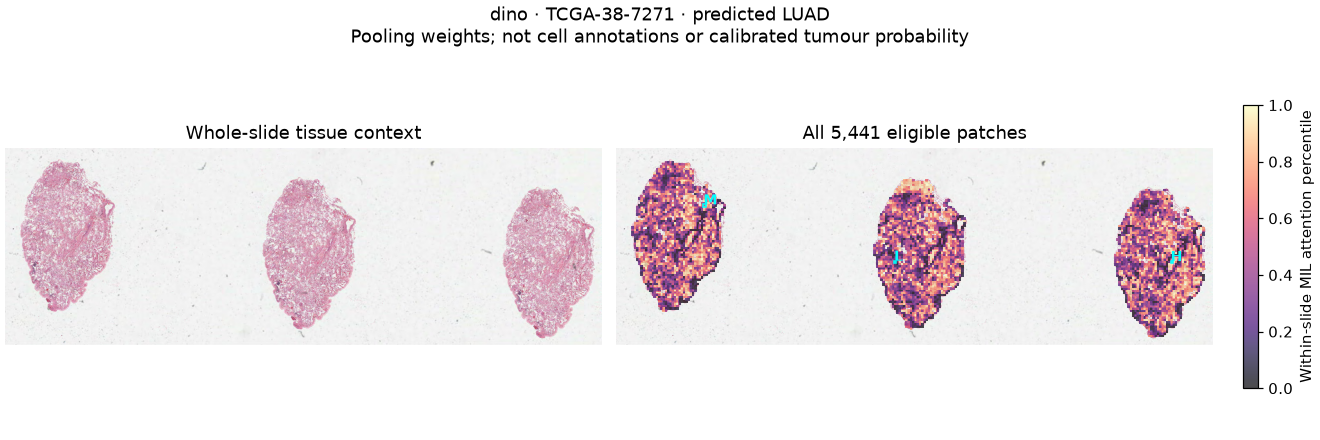

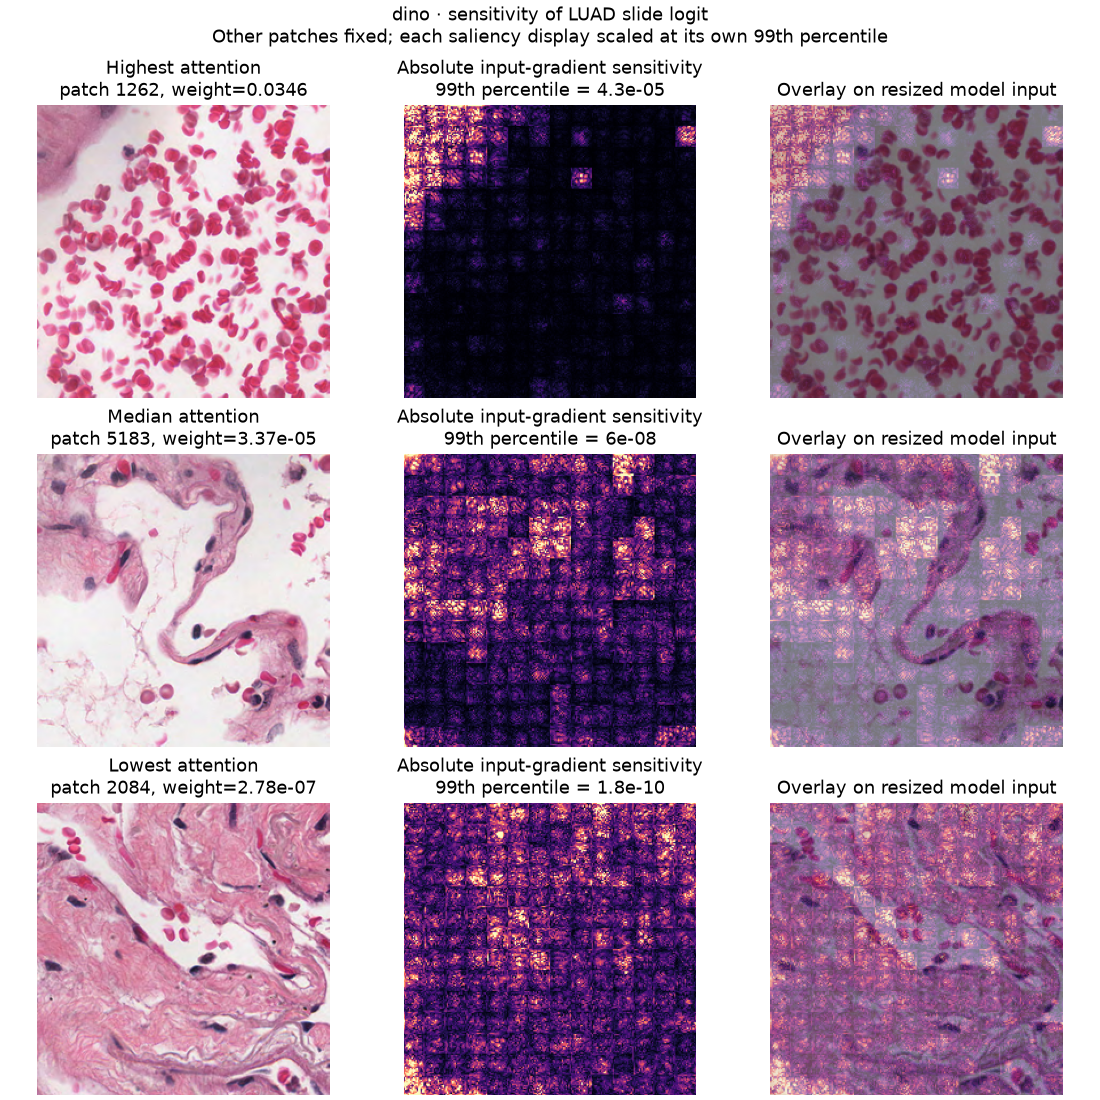

resnet50 481320d0-3239-4a35-9264-89ae40af4190


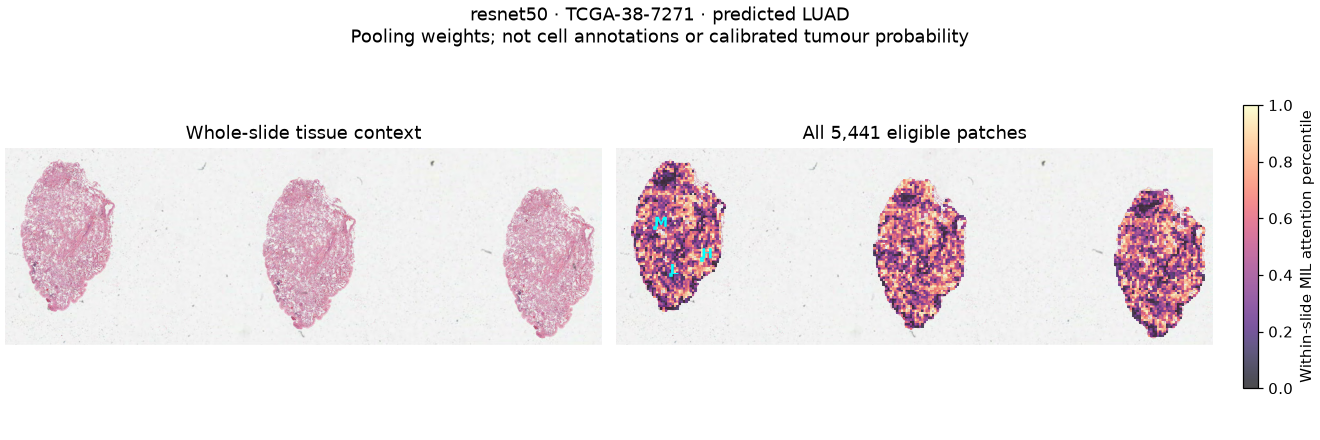

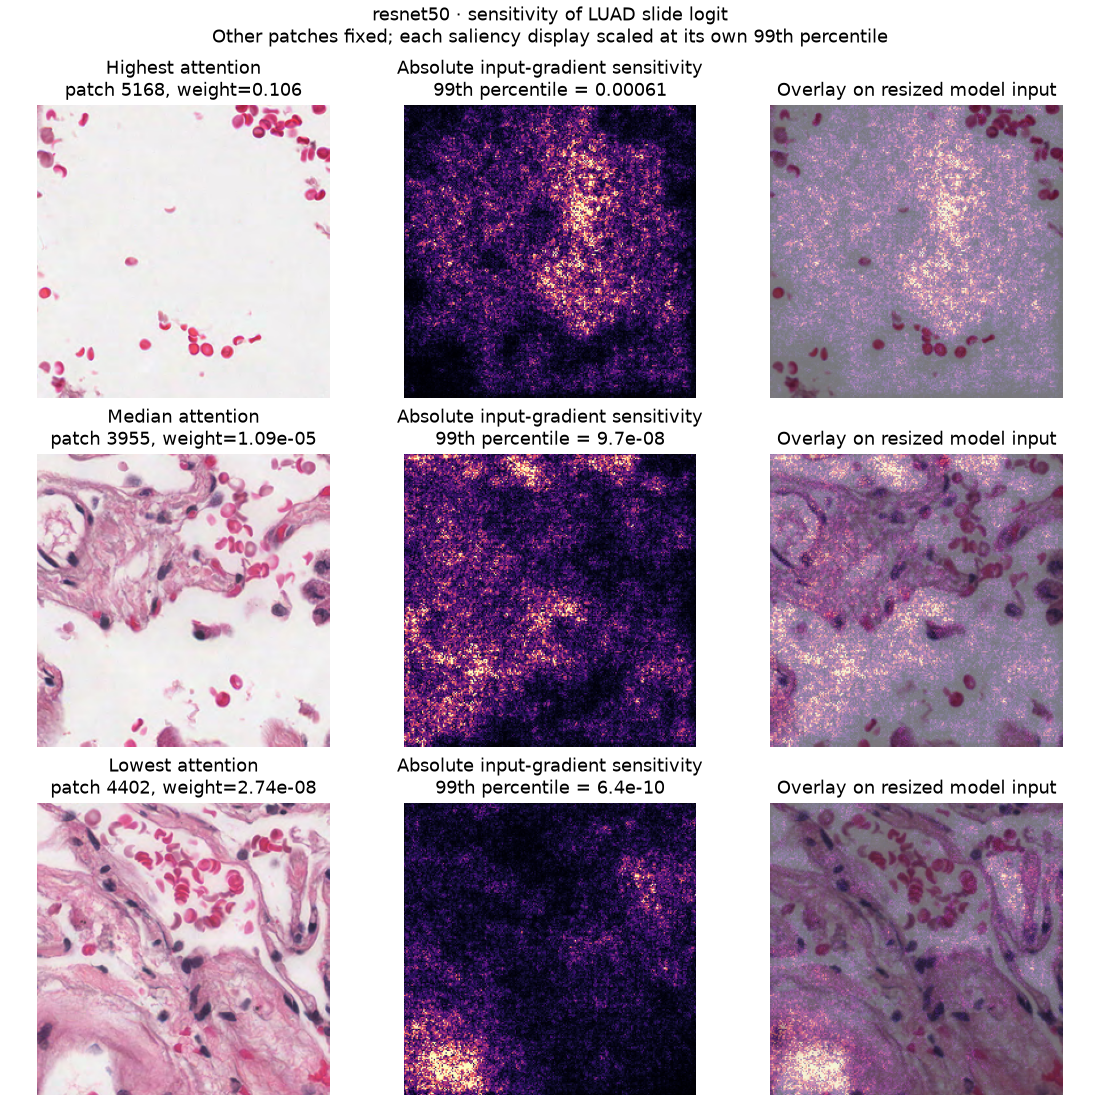

In [6]:
DISPLAY_SLIDE = sorted(row['bag_id'] for row in rows if row['split'] == 'test')[0]
for name in comparison['models']:
    folder = OUT / 'comparison' / name / 'interpretation' / DISPLAY_SLIDE
    print(name, DISPLAY_SLIDE)
    display(DisplayImage(filename=str(folder / 'slide_attention.png')))
    display(DisplayImage(filename=str(folder / 'selected_patch_saliency.png')))

## 7. Evidence and limits

The receipt records complete feature-cache coverage, model hashes, patient splits, optimization history, selected checkpoints and interpretation targets. Frozen features from test slides are computed without labels; training and checkpoint selection use only their declared splits. Existing tissue eligibility is a preprocessing decision, not a tumour annotation.


In [7]:
for source in source_state.values():
    current = Path(source['path']).stat()
    assert (current.st_size, current.st_mtime_ns) == (source['size_bytes'], source['mtime_ns'])
    assert sha256(source['coords_path']) == source['coords_sha256']
receipt = {'status': 'complete', 'split_manifest': str(manifest), 'split_sha256': sha256(manifest),
    'preprocessing_manifest': str(preprocessing_manifest_path), 'preprocessing_sha256': sha256(preprocessing_manifest_path),
    'source_files': source_state, 'same_patient_split_across_models': True,
    'all_eligible_patches_per_encoder': int(coverage['eligible_patches'].sum()),
    'comparison_receipt': str(OUT / 'comparison/comparison_receipt.json'),
    'elapsed_seconds': time.monotonic() - started,
    'interpretation': 'Frozen encoders plus trained slide classifiers; ten-patient teaching comparison'}
(OUT / 'run_receipt.json').write_text(json.dumps(receipt, indent=2, allow_nan=False))
print('Outputs:', OUT)

Outputs: /Users/irina/Projects/digital-pathology-demo/outputs/learning_recipes_validation_20261103/classification-publish-validation/runs/20261103T212408Z_cbe103f2


## Pretrained model provenance

| Exact encoder | Training strategy before this demo | Pretraining data |
| --- | --- | --- |
| **Original UNI**, ViT-L/16 (`MahmoodLab/UNI`, not UNI2) | DINOv2 self-supervision: multi-crop teacher/student self-distillation, an iBOT masked-image objective and KoLeo regularization. | **Mass-100K**: approximately 100 million H&E patches from more than 100,000 WSIs across 20 organs, sourced from BWH, MGH and GTEx. [Model card](https://huggingface.co/MahmoodLab/UNI), [paper](https://www.nature.com/articles/s41591-024-02857-3). |
| **DINO ViT-S/16** (`timm/vit_small_patch16_224.dino`) | Self-supervised multi-crop teacher/student distillation without diagnosis or ImageNet class labels. | **ImageNet-1k** images. [Exact model card](https://huggingface.co/timm/vit_small_patch16_224.dino), [DINO paper](https://arxiv.org/abs/2104.14294). |
| **ResNet-50 IMAGENET1K_V2** (`resnet50-11ad3fa6.pth`) | Supervised 1,000-class classification with TorchVision's improved training recipe. | **ImageNet-1k**. [Official weights and recipe](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html). |

This demo freezes each encoder and trains only the slide-level attention/classification head on the declared TCGA-LUAD/LUSC training patients. Validation selects the checkpoint; held-out labels do not enter training. Pretraining provenance describes initialization, not generalization or a guarantee of disease-specific representations.
